In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

input_dir = Path("inputs")
annotation_dir = Path("annotations")
output_dir = Path("outputs/challenge_1_results")
output_dir.mkdir(exist_ok=True)

# Load the annotated finish labels
parts_df = pd.read_csv(annotation_dir / "parts.csv")

display(parts_df.head())

print("\nFinish distribution:")
print(parts_df["finish"].value_counts(dropna=False))


,image,part_id,type,finish,head_x,head_y,notes
0,screws_026.png,1,screw,black-oxidized_steel,592.5,1099.5,NaN
1,screws_026.png,2,screw,stainless_steel,990.0,942.5,NaN
2,screws_026.png,3,screw,black-oxidized_steel,716.5,78.5,NaN
3,screws_026.png,4,screw,black-oxidized_steel,1183.0,364.5,NaN
4,screws_026.png,5,screw,stainless_steel,216.5,480.0,NaN



Finish distribution:
finish
stainless_steel             37
black-oxidized_steel        22
hot-dip_galvanized_steel    14
yellow_zinc-plated_steel    12
Name: count, dtype: int64


For each annotated image capture: 
Feature	Reason
LAB L* median	Distinguishes lighter and darker finishes
LAB a* median	Captures green–red differences
LAB b* median	Captures blue–yellow differences
HSV saturation median	Helps distinguish coloured from neutral finishes
LAB L* standard deviation	Captures brightness variability and reflections
HSV saturation standard deviation	Captures variation in colour intensity


Justification should be from challenge 1 which shows that LAB gives best seperation across colour channels. Using 6 channels and metrics is enough to start. 

Choosing median to eliminate noise -> sometimes illumination on screws makes it look white. 

In [47]:
def extract_colour_features(image_path, label_path):
    """
    Extract colour statistics for each ground-truth object.
    Each row represents one screw or nut.
    """

    img = cv2.imread(str(image_path))
    labels = cv2.imread(str(label_path), cv2.IMREAD_UNCHANGED)

    if img is None or labels is None:
        raise FileNotFoundError(
            f"Missing image or labels: {image_path}, {label_path}"
        )

    if labels.ndim != 2 or img.shape[:2] != labels.shape:
        raise ValueError("Invalid label image dimensions.")

    # Convert to LAB and HSV colour spaces
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    rows = []

    for part_id in np.unique(labels):
        if part_id == 0:
            continue

        # Extract only pixels belonging to this part
        mask = labels == part_id

        lab_pixels = lab[mask]
        hsv_pixels = hsv[mask]

        rows.append({
            "image": Path(image_path).name,
            "part_id": int(part_id),
            "area": int(mask.sum()),

            "L_median": np.median(lab_pixels[:, 0]),
            "a_median": np.median(lab_pixels[:, 1]),
            "b_median": np.median(lab_pixels[:, 2]),
            "S_median": np.median(hsv_pixels[:, 1]),

            "L_std": np.std(lab_pixels[:, 0]),
            "S_std": np.std(hsv_pixels[:, 1]),

            # additional features for brightness robustion
            "L_p25": np.percentile(lab_pixels[:, 0], 25),
            "S_p75": np.percentile(hsv_pixels[:, 1], 75),
        })

    return pd.DataFrame(rows)


# Extract features from all annotated images
feature_tables = []

for image_path in sorted(input_dir.iterdir()):

    if image_path.suffix.lower() not in {
        ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
    }:
        continue

    label_path = (
        annotation_dir / f"{image_path.stem}_labels.png"
    )

    if not label_path.exists():
        continue  # This image has no ground-truth labels

    feature_tables.append(
        extract_colour_features(image_path, label_path)
    )

if not feature_tables:
    raise ValueError("No annotated images found.")

features_df = pd.concat(feature_tables, ignore_index=True)

# Attach the true finish of each annotated part
dataset = features_df.merge(
    parts_df[["image", "part_id", "finish","type"]],
    on=["image", "part_id"],
    how="left",
    validate="one_to_one"
)

if dataset["finish"].isna().any():
    missing = dataset[dataset["finish"].isna()]
    display(missing[["image", "part_id"]])
    raise ValueError("Some detected ground-truth parts have no finish annotation.")

display(dataset.head().round(2))


,image,part_id,area,L_median,a_median,b_median,S_median,L_std,S_std,L_p25,S_p75,finish,type
0,screws_026.png,1,10371,31.0,129.0,131.0,58.0,14.73,32.65,27.0,80.0,black-oxidized_steel,screw
1,screws_026.png,2,11319,107.0,132.0,146.0,110.0,50.85,42.48,84.0,135.0,stainless_steel,screw
2,screws_026.png,3,13488,17.0,129.0,130.0,78.0,19.97,41.56,10.0,112.0,black-oxidized_steel,screw
3,screws_026.png,4,10967,31.0,129.0,132.0,62.0,19.97,38.96,27.0,88.0,black-oxidized_steel,screw
4,screws_026.png,5,11203,98.0,132.0,144.0,107.0,47.28,42.73,79.0,135.0,stainless_steel,screw


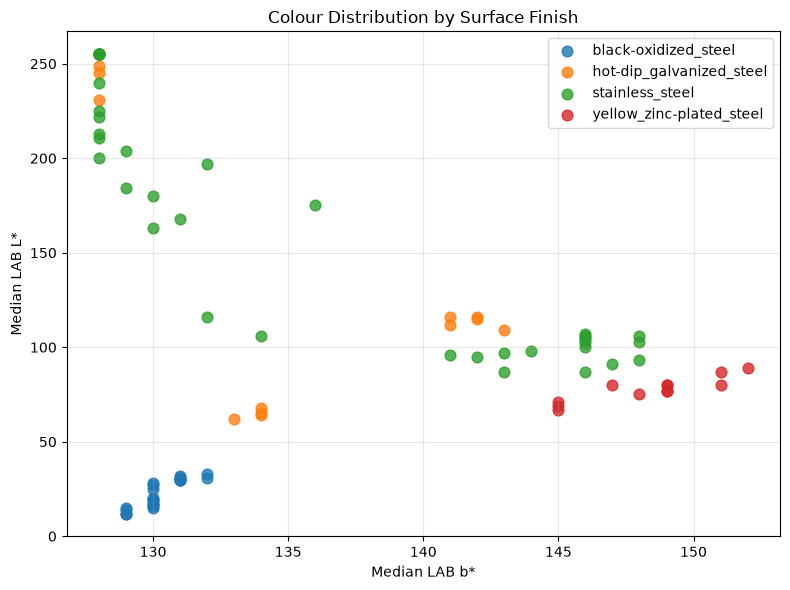

In [4]:
plt.figure(figsize=(8, 6))

for finish, group in dataset.groupby("finish"):
    plt.scatter(
        group["b_median"],
        group["L_median"],
        label=finish,
        alpha=0.8,
        s=60
    )

plt.xlabel("Median LAB b*")
plt.ylabel("Median LAB L*")
plt.title("Colour Distribution by Surface Finish")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Choose the features
feature_cols = [
    "L_median",
    "a_median",
    "b_median",
    "S_median",
    "L_std",
    "S_std",
]

X = dataset[feature_cols]
y = dataset["finish"]
groups = dataset["image"]

# Split by image, keeping entire images together
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.3,
    random_state=10  #random state 
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Check that all test finishes are represented in training
missing_classes = set(y_test) - set(y_train)

if missing_classes:
    raise ValueError(
        f"These finishes are absent from training: {missing_classes}. "
        "Use a different image-level split."
    )

# Standardization + k-NN
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

# Train
knn.fit(X_train, y_train)

# Predict on held-out images
y_pred = knn.predict(X_test)

print("Training images:", groups.iloc[train_idx].nunique())
print("Testing images:", groups.iloc[test_idx].nunique())

print(f"\nTest accuracy: {accuracy_score(y_test, y_pred):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


Training images: 7
Testing images: 3

Test accuracy: 1.0000

Classification report:
                          precision    recall  f1-score   support

    black-oxidized_steel       1.00      1.00      1.00         6
hot-dip_galvanized_steel       1.00      1.00      1.00         4
         stainless_steel       1.00      1.00      1.00         9
yellow_zinc-plated_steel       1.00      1.00      1.00         6

                accuracy                           1.00        25
               macro avg       1.00      1.00      1.00        25
            weighted avg       1.00      1.00      1.00        25



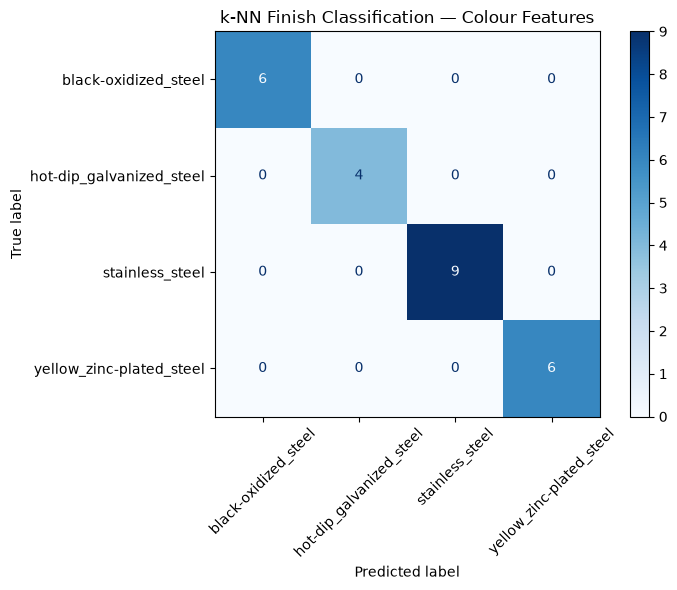

In [15]:

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("k-NN Finish Classification — Colour Features")

plt.tight_layout()
plt.show()


In [16]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from skimage.feature import graycoprops


def extract_glcm_features(image_path, label_path):
    """
    Extract GLCM texture features for each annotated part.

    Only neighbouring pixels within the part are used.
    """

    img = cv2.imread(str(image_path))
    labels = cv2.imread(str(label_path), cv2.IMREAD_UNCHANGED)

    if img is None or labels is None:
        raise FileNotFoundError("Could not read image or labels.")

    if labels.ndim != 2 or img.shape[:2] != labels.shape:
        raise ValueError("Image and labels have incompatible dimensions.")

    # Convert to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Reduce from 256 to 32 grey levels
    levels = 32
    gray = gray // 8

    # Neighbour offsets for 0, 45, 90 and 135 degrees
    offsets = [(0, 1), (1, 1), (1, 0), (1, -1)]

    rows = []

    for part_id in np.unique(labels):

        if part_id == 0:
            continue

        mask = labels == part_id

        # GLCM shape expected by skimage:
        # (grey levels, grey levels, distances, angles)
        glcm = np.zeros(
            (levels, levels, 1, 4),
            dtype=np.float64
        )

        valid_pairs = 0

        for angle_idx, (dy, dx) in enumerate(offsets):

            # Coordinates of overlapping image regions
            y1 = max(0, -dy)
            y2 = gray.shape[0] - max(0, dy)
            x1 = max(0, -dx)
            x2 = gray.shape[1] - max(0, dx)

            a = gray[y1:y2, x1:x2]
            b = gray[y1+dy:y2+dy, x1+dx:x2+dx]

            mask_a = mask[y1:y2, x1:x2]
            mask_b = mask[y1+dy:y2+dy, x1+dx:x2+dx]

            # Both neighbouring pixels must belong to this part
            valid = mask_a & mask_b

            p = a[valid]
            q = b[valid]

            valid_pairs += len(p)

            # Count neighbouring grey-level combinations
            np.add.at(glcm[:, :, 0, angle_idx], (p, q), 1)
            np.add.at(glcm[:, :, 0, angle_idx], (q, p), 1)

            # Normalize the GLCM
            total = glcm[:, :, 0, angle_idx].sum()

            if total > 0:
                glcm[:, :, 0, angle_idx] /= total

        # Avoid interpreting an empty matrix as valid texture
        if valid_pairs == 0:
            contrast = homogeneity = energy = np.nan
        else:
            contrast = graycoprops(glcm, "contrast").mean()
            homogeneity = graycoprops(glcm, "homogeneity").mean()
            energy = graycoprops(glcm, "energy").mean()

        rows.append({
            "image": Path(image_path).name,
            "part_id": int(part_id),
            "GLCM_contrast": contrast,
            "GLCM_homogeneity": homogeneity,
            "GLCM_energy": energy,
            "GLCM_pairs": valid_pairs
        })

    return pd.DataFrame(rows)


In [48]:

glcm_tables = []

for image_path in sorted(input_dir.iterdir()):

    if image_path.suffix.lower() not in {
        ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
    }:
        continue

    label_path = (
        annotation_dir / f"{image_path.stem}_labels.png"
    )

    if not label_path.exists():
        continue

    features = extract_glcm_features(
        image_path,
        label_path
    )

    glcm_tables.append(features)

if not glcm_tables:
    raise ValueError("No annotated images found.")

glcm_df = pd.concat(glcm_tables, ignore_index=True)

# Add GLCM features to the existing colour dataset
dataset_glcm = dataset.merge(
    glcm_df,
    on=["image", "part_id"],
    how="left",
    validate="one_to_one"
)

glcm_cols = [
    "GLCM_contrast",
    "GLCM_homogeneity",
    "GLCM_energy"
]

# Check missing values before classification
print("Missing GLCM features:")
print(dataset_glcm[glcm_cols].isna().sum())

display(dataset_glcm[
    ["image", "part_id", "finish","type"] + glcm_cols + ["GLCM_pairs"]
].head(10).round(3))


Missing GLCM features:
GLCM_contrast       0
GLCM_homogeneity    0
GLCM_energy         0
dtype: int64


,image,part_id,finish,type,GLCM_contrast,GLCM_homogeneity,GLCM_energy,GLCM_pairs
0,screws_026.png,1,black-oxidized_steel,screw,0.907,0.840,0.509,40000
1,screws_026.png,2,stainless_steel,screw,9.473,0.491,0.109,43984
2,screws_026.png,3,black-oxidized_steel,screw,0.945,0.778,0.353,52579
3,screws_026.png,4,black-oxidized_steel,screw,1.503,0.822,0.491,42474
4,screws_026.png,5,stainless_steel,screw,7.848,0.518,0.127,43254
5,screws_026.png,6,black-oxidized_steel,screw,1.061,0.780,0.420,53585
6,screws_026.png,7,stainless_steel,nut,14.101,0.583,0.377,8910
7,screws_026.png,8,stainless_steel,nut,8.465,0.711,0.568,9671
8,screws_027.png,1,black-oxidized_steel,screw,0.864,0.842,0.512,40776
9,screws_027.png,2,stainless_steel,nut,13.646,0.548,0.293,10362


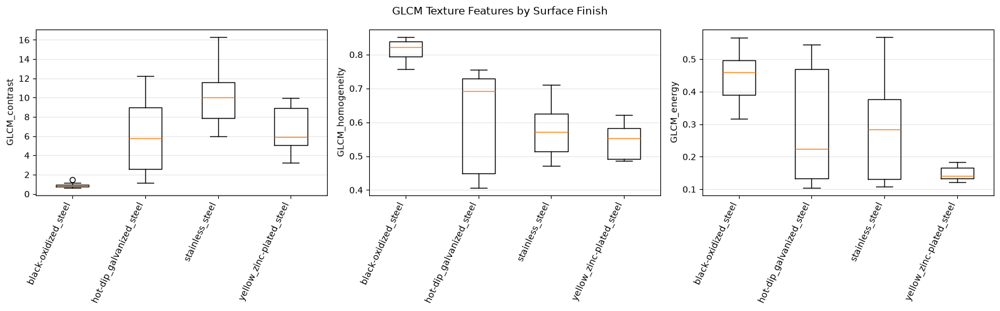

In [18]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, glcm_cols):

    data_by_finish = [
        group[feature].dropna().values
        for _, group in dataset_glcm.groupby("finish")
    ]

    finish_names = [
        name
        for name, _ in dataset_glcm.groupby("finish")
    ]

    ax.boxplot(data_by_finish)
    ax.set_xticks(range(1, len(finish_names) + 1))
    ax.set_xticklabels(finish_names, rotation=65, ha="right")
    ax.set_ylabel(feature)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("GLCM Texture Features by Surface Finish")
plt.tight_layout()
plt.show()


In [19]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Feature sets to compare
feature_sets = {
    "Colour": feature_cols,
    "GLCM": glcm_cols,
    "Colour + GLCM": feature_cols + glcm_cols
}

# Confirm that the merged dataset has the same row order
assert dataset_glcm[["image", "part_id"]].equals(
    dataset[["image", "part_id"]]
)

if dataset_glcm[feature_cols + glcm_cols].isna().any().any():
    raise ValueError("Some feature values are missing.")

results = []

for method_name, columns in feature_sets.items():

    # Use the same training/testing objects for every method
    X_train = dataset_glcm.iloc[train_idx][columns]
    X_test = dataset_glcm.iloc[test_idx][columns]

    y_train = dataset_glcm.iloc[train_idx]["finish"]
    y_test = dataset_glcm.iloc[test_idx]["finish"]

    # Standardize features and train k-NN
    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)
    )

    knn.fit(X_train, y_train)

    # Predict finishes
    y_pred = knn.predict(X_test)

    # Evaluate classification
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Method": method_name,
        "Accuracy": accuracy
    })

    print(f"\n--- {method_name} ---")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

# Display comparison
results_df = pd.DataFrame(results)

display(results_df.round(4))



--- Colour ---
                          precision    recall  f1-score   support

    black-oxidized_steel       1.00      1.00      1.00         6
hot-dip_galvanized_steel       1.00      1.00      1.00         4
         stainless_steel       1.00      1.00      1.00         9
yellow_zinc-plated_steel       1.00      1.00      1.00         6

                accuracy                           1.00        25
               macro avg       1.00      1.00      1.00        25
            weighted avg       1.00      1.00      1.00        25


--- GLCM ---
                          precision    recall  f1-score   support

    black-oxidized_steel       1.00      1.00      1.00         6
hot-dip_galvanized_steel       1.00      1.00      1.00         4
         stainless_steel       0.73      0.89      0.80         9
yellow_zinc-plated_steel       0.75      0.50      0.60         6

                accuracy                           0.84        25
               macro avg       0.87      

,Method,Accuracy
0,Colour,1.00
1,GLCM,0.84
2,Colour + GLCM,1.00


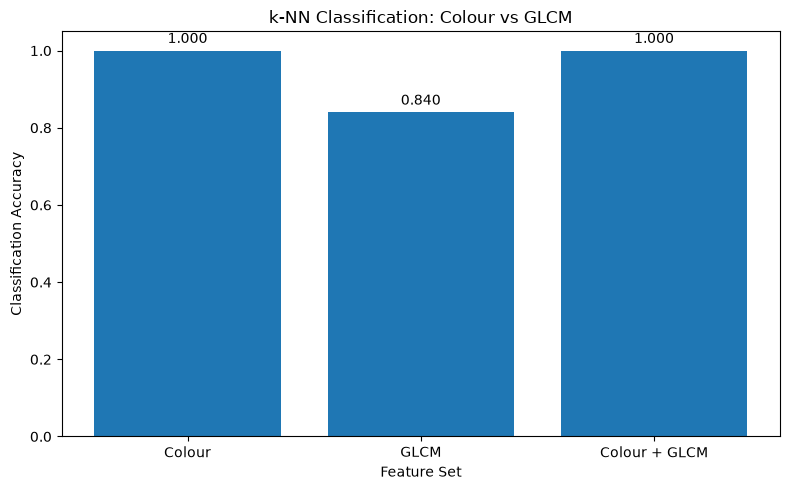

In [20]:

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Method"],
    results_df["Accuracy"]
)

plt.ylabel("Classification Accuracy")
plt.xlabel("Feature Set")
plt.title("k-NN Classification: Colour vs GLCM")
plt.ylim(0, 1.05)

for i, accuracy in enumerate(results_df["Accuracy"]):
    plt.text(
        i,
        accuracy + 0.02,
        f"{accuracy:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


In [21]:

from sklearn.model_selection import GroupKFold, cross_val_score

X_groups = dataset_glcm["image"]
y = dataset_glcm["finish"]

# Five-fold cross-validation grouped by image
cv = GroupKFold(n_splits=5)

cv_results = []

for method_name, columns in feature_sets.items():

    X = dataset_glcm[columns]

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)
    )

    scores = cross_val_score(
        model,
        X,
        y,
        groups=X_groups,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "Method": method_name,
        "Mean Accuracy": scores.mean(),
        "Std Accuracy": scores.std()
    })

    print(f"{method_name}: {scores.round(3)}")

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))


Colour: [0.944 1.    1.    1.    0.875]
GLCM: [0.889 1.    1.    0.824 0.688]
Colour + GLCM: [1.    1.    1.    1.    0.938]


,Method,Mean Accuracy,Std Accuracy
0,Colour,0.9639,0.0494
1,GLCM,0.8800,0.1176
2,Colour + GLCM,0.9875,0.0250


In [22]:

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Same cross-validation setup as before
cv = GroupKFold(n_splits=5)

# Same feature sets
feature_sets = {
    "Colour": feature_cols,
    "GLCM": glcm_cols,
    "Colour + GLCM": feature_cols + glcm_cols
}

# Store predictions and mistakes for each method
predictions = {}
errors = {}

for method_name, columns in feature_sets.items():

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)
    )

    # Predict every object using an unseen-image fold
    y_pred_cv = cross_val_predict(
        model,
        dataset_glcm[columns],
        dataset_glcm["finish"],
        groups=dataset_glcm["image"],
        cv=cv
    )

    predictions[method_name] = y_pred_cv

    # Find incorrectly classified objects
    wrong = dataset_glcm.loc[
        y_pred_cv != dataset_glcm["finish"].to_numpy(),
        ["image", "part_id", "finish"]
    ].copy()

    wrong["predicted_finish"] = y_pred_cv[
        y_pred_cv != dataset_glcm["finish"].to_numpy()
    ]

    errors[method_name] = wrong

    print(f"{method_name}: {len(wrong)} misclassified objects")

# Inspect the colour classifier mistakes
display(errors["Colour"])


Colour: 3 misclassified objects
GLCM: 10 misclassified objects
Colour + GLCM: 1 misclassified objects


,image,part_id,finish,predicted_finish
36,screws_040.png,5,hot-dip_galvanized_steel,stainless_steel
66,screws_061.png,7,yellow_zinc-plated_steel,stainless_steel
73,screws_063.png,6,yellow_zinc-plated_steel,stainless_steel


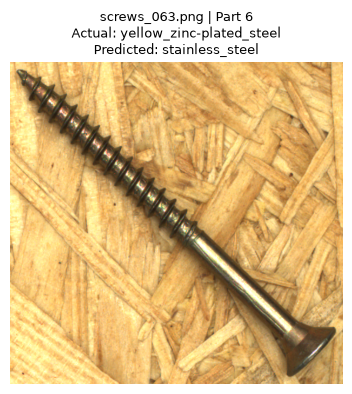

In [25]:

def show_classification_errors(error_df, max_objects=12):
    """
    Display cropped images of incorrectly classified parts.
    Uses ground-truth segmentation masks.
    """

    if error_df.empty:
        print("No classification errors.")
        return

    error_df = error_df.head(max_objects)

    n = len(error_df)
    ncols = min(4, n)
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4 * ncols, 4 * nrows),
        squeeze=False
    )

    axes = axes.ravel()

    for ax, (_, row) in zip(axes, error_df.iterrows()):

        image_path = Path("inputs") / row["image"]

        label_path = (
            Path("annotations") /
            f"{Path(row['image']).stem}_labels.png"
        )

        img = cv2.imread(str(image_path))
        labels = cv2.imread(
            str(label_path),
            cv2.IMREAD_UNCHANGED
        )

        mask = labels == int(row["part_id"])

        ys, xs = np.where(mask)

        # Bounding box with a small margin
        margin = 10

        x1 = max(0, xs.min() - margin)
        x2 = min(img.shape[1], xs.max() + margin + 1)

        y1 = max(0, ys.min() - margin)
        y2 = min(img.shape[0], ys.max() + margin + 1)

        crop = cv2.cvtColor(
            img[y1:y2, x1:x2],
            cv2.COLOR_BGR2RGB
        )

        ax.imshow(crop)

        ax.set_title(
            f"{row['image']} | Part {row['part_id']}\n"
            f"Actual: {row['finish']}\n"
            f"Predicted: {row['predicted_finish']}",
            fontsize=9
        )

        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# Display the colour classifier's mistakes
show_classification_errors(errors["Colour + GLCM"])


In [26]:

# Identify the incorrectly classified screw
wrong = errors["Colour"].iloc[0]

# Extract its features
wrong_part = dataset_glcm[
    (dataset_glcm["image"] == wrong["image"]) &
    (dataset_glcm["part_id"] == wrong["part_id"])
]

# Compare against the yellow-zinc class
yellow_parts = dataset_glcm[
    dataset_glcm["finish"] == "yellow_zinc-plated_steel"
]

cols = [
    "L_median",
    "a_median",
    "b_median",
    "S_median",
    "GLCM_contrast",
    "GLCM_homogeneity",
    "GLCM_energy"
]

comparison = pd.DataFrame({
    "Misclassified screw": wrong_part[cols].iloc[0],
    "Yellow-zinc median": yellow_parts[cols].median(),
    "Yellow-zinc std": yellow_parts[cols].std()
})

display(comparison.round(2))


,Misclassified screw,Yellow-zinc median,Yellow-zinc std
L_median,231.00,78.50,6.60
a_median,128.00,132.00,0.62
b_median,128.00,149.00,2.42
S_median,19.00,143.00,8.66
GLCM_contrast,4.97,5.93,2.31
GLCM_homogeneity,0.74,0.55,0.05
GLCM_energy,0.47,0.14,0.02


In [39]:

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np

# Original six colour features
original_features = [
    "L_median",
    "a_median",
    "b_median",
    "S_median",
    "L_std",
    "S_std"
]

# Add the two new percentile features
modified_features = original_features + [
    "L_p25",
    "S_p75"
]

feature_sets = {
    "Original colour": original_features,
    "Colour + percentiles": modified_features
}

cv = GroupKFold(n_splits=5)

y = dataset_glcm["finish"]
groups = dataset_glcm["image"]

results = []
predictions_percentiles = {}

for name, cols in feature_sets.items():

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)
    )

    # Predict each part using a model trained on other images
    y_pred = cross_val_predict(
        model,
        dataset_glcm[cols],
        y,
        groups=groups,
        cv=cv
    )

    predictions_percentiles[name] = y_pred

    results.append({
        "Method": name,
        "Accuracy": accuracy_score(y, y_pred),
        "Errors": np.sum(y_pred != y.to_numpy())
    })

results_percentiles_df = pd.DataFrame(results)

display(results_percentiles_df.round(4))


,Method,Accuracy,Errors
0,Original colour,0.9647,3
1,Colour + percentiles,0.9765,2


In [43]:
actual = dataset_glcm["finish"].to_numpy()

original_pred = predictions_percentiles["Original colour"]
modified_pred = predictions_percentiles["Colour + percentiles"]

# Parts corrected by adding percentile features
fixed = (original_pred != actual) & (modified_pred == actual)

# Parts that become incorrect
worsened = (original_pred == actual) & (modified_pred != actual)

print("Errors corrected:", fixed.sum())
print("New errors introduced:", worsened.sum())

# Show objects whose classifications improved
fixed_parts = dataset_glcm.loc[
    fixed, ["image", "part_id", "finish"]
].copy()

fixed_parts["original_prediction"] = original_pred[fixed]
fixed_parts["new_prediction"] = modified_pred[fixed]

display(fixed_parts)

Errors corrected: 1
New errors introduced: 0


,image,part_id,finish,original_prediction,new_prediction
66,screws_061.png,7,yellow_zinc-plated_steel,stainless_steel,yellow_zinc-plated_steel


In [44]:
# True finish labels
actual = dataset_glcm["finish"].to_numpy()

# Predictions using the new percentile features
predicted = predictions_percentiles["Colour + percentiles"]

# Identify incorrect predictions
wrong_mask = predicted != actual

# Create a table of misclassified objects
wrong_parts = dataset_glcm.loc[
    wrong_mask, ["image", "part_id", "finish"]
].copy()

wrong_parts["predicted_finish"] = predicted[wrong_mask]

print(f"Total misclassified parts: {len(wrong_parts)}")
display(wrong_parts)

Total misclassified parts: 2


,image,part_id,finish,predicted_finish
36,screws_040.png,5,hot-dip_galvanized_steel,stainless_steel
73,screws_063.png,6,yellow_zinc-plated_steel,stainless_steel


In [49]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Same nine features as your combined classifier
combined_features = feature_cols + glcm_cols

# Split by image
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.3,
    random_state=10
)

train_idx, test_idx = next(
    splitter.split(
        dataset_glcm,
        dataset_glcm["finish"],
        groups=dataset_glcm["image"]
    )
)

train_data = dataset_glcm.iloc[train_idx]
test_data = dataset_glcm.iloc[test_idx]

# Train with ground-truth masks only
model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

model.fit(
    train_data[combined_features],
    train_data["finish"]
)

# Reference accuracy using perfect masks
gt_predictions = model.predict(test_data[combined_features])

print("Test images:", test_data["image"].unique())

print(
    "Accuracy with ground-truth masks:",
    round(accuracy_score(test_data["finish"], gt_predictions), 4)
)


Test images: <StringArray>
['screws_028.png', 'screws_041.png', 'screws_063.png']
Length: 3, dtype: str
Accuracy with ground-truth masks: 1.0


In [50]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Use the best-performing feature combination
combined_features = feature_cols + glcm_cols

# Create final classifier
final_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

# Train on all available annotated objects
final_knn.fit(
    dataset_glcm[combined_features],
    dataset_glcm["finish"]
)

print("Final k-NN classifier trained.")
print("Training objects:", len(dataset_glcm))


Final k-NN classifier trained.
Training objects: 85


In [53]:

from pathlib import Path
import pandas as pd
import numpy as np

input_dir = Path("inputs")
prediction_dir = Path("outputs/challenge_1_results")
output_dir = Path("outputs/challenge_3_results")

output_dir.mkdir(parents=True, exist_ok=True)

combined_features = feature_cols + glcm_cols

all_predictions = []

# Automatically find all Challenge 1 label images
label_paths = sorted(
    prediction_dir.glob("*_label_image.png")
)

for label_path in label_paths:

    # Example:
    # screws_026_label_image.png -> screws_026
    image_stem = label_path.name.removesuffix("_label_image.png")

    # Find the corresponding original image
    matches = [
        p for p in input_dir.glob(f"{image_stem}.*")
        if p.suffix.lower() in {
            ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
        }
    ]

    if len(matches) != 1:
        print(f"Skipping {image_stem}: expected one original image.")
        continue

    image_path = matches[0]

    # Extract features using Challenge 1 predicted masks
    colour = extract_colour_features(image_path, label_path)
    glcm = extract_glcm_features(image_path, label_path)

    features = colour.merge(
        glcm,
        on=["image", "part_id"],
        validate="one_to_one"
    )

    if features.empty:
        continue

    # Identify components with valid features
    valid = features[combined_features].notna().all(axis=1)

    features["predicted_finish"] = "unclassified"

    features.loc[valid, "predicted_finish"] = (
        final_knn.predict(
            features.loc[valid, combined_features]
        )
    )

    all_predictions.append(
        features[["image", "part_id", "predicted_finish"]]
    )

# Combine predictions
if not all_predictions:
    raise ValueError("No valid Challenge 1 detections found.")

finish_results = pd.concat(
    all_predictions,
    ignore_index=True
)

# Save results
finish_results.to_csv(
    output_dir / "predicted_finishes.csv",
    index=False
)

print(f"Processed {finish_results['image'].nunique()} images.")
print(f"Classified {len(finish_results)} detected components.")

display(finish_results.head(20))


Processed 10 images.
Classified 86 detected components.


,image,part_id,predicted_finish
0,screws_026.png,1,black-oxidized_steel
1,screws_026.png,2,black-oxidized_steel
2,screws_026.png,3,stainless_steel
3,screws_026.png,4,stainless_steel
4,screws_026.png,5,stainless_steel
5,screws_026.png,6,stainless_steel
6,screws_026.png,7,black-oxidized_steel
7,screws_026.png,8,black-oxidized_steel
8,screws_027.png,1,stainless_steel
9,screws_027.png,2,stainless_steel


In [57]:

import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment


def match_parts(pred_labels, gt_labels, min_iou=0.3):
    """
    Match predicted objects to ground-truth objects using IoU.

    Parameters
    ----------
    pred_labels : 2D array
        Challenge 1 label image (0 = background).
    gt_labels : 2D array
        Ground-truth label image (0 = background).
    min_iou : float
        Minimum IoU required to accept a match.

    Returns
    -------
    DataFrame with columns:
        pred_id, gt_id, match_iou
    """

    if pred_labels.shape != gt_labels.shape:
        raise ValueError("Predicted and GT label images have different shapes.")

    # Extract object IDs, excluding background
    pred_ids = np.unique(pred_labels)
    pred_ids = pred_ids[pred_ids != 0]

    gt_ids = np.unique(gt_labels)
    gt_ids = gt_ids[gt_ids != 0]

    columns = ["pred_id", "gt_id", "match_iou"]

    if len(pred_ids) == 0 or len(gt_ids) == 0:
        return pd.DataFrame(columns=columns)

    # Compute IoU for every predicted/GT object pair
    iou_matrix = np.zeros((len(pred_ids), len(gt_ids)))

    for i, pred_id in enumerate(pred_ids):
        pred_mask = pred_labels == pred_id

        for j, gt_id in enumerate(gt_ids):
            gt_mask = gt_labels == gt_id

            intersection = np.logical_and(
                pred_mask, gt_mask
            ).sum()

            union = np.logical_or(
                pred_mask, gt_mask
            ).sum()

            iou_matrix[i, j] = (
                intersection / union if union > 0 else 0
            )

    # Find optimal one-to-one assignments
    pred_indices, gt_indices = linear_sum_assignment(
        -iou_matrix
    )

    matches = []

    for i, j in zip(pred_indices, gt_indices):

        score = iou_matrix[i, j]

        if score >= min_iou:
            matches.append({
                "pred_id": int(pred_ids[i]),
                "gt_id": int(gt_ids[j]),
                "match_iou": float(score)
            })

    return pd.DataFrame(matches, columns=columns)


In [55]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt


def evaluate_predicted_finishes(
    finish_results,
    parts_df,
    annotation_dir=Path("annotations"),
    prediction_dir=Path("outputs/challenge_1_results"),
    min_iou=0.3
):
    matches_list = []
    counts = []

    # Only evaluate images for which ground truths exist
    for image_name in sorted(finish_results["image"].unique()):

        stem = Path(image_name).stem

        gt_path = annotation_dir / f"{stem}_labels.png"
        pred_path = prediction_dir / f"{stem}_label_image.png"

        if not gt_path.exists() or not pred_path.exists():
            continue

        gt_labels = cv2.imread(str(gt_path), cv2.IMREAD_UNCHANGED)
        pred_labels = cv2.imread(str(pred_path), cv2.IMREAD_UNCHANGED)

        if gt_labels is None or pred_labels is None:
            raise ValueError(f"Could not read labels for {image_name}")

        matches = match_parts(
            pred_labels,
            gt_labels,
            min_iou=min_iou
        )

        matches["image"] = image_name
        matches_list.append(matches)

        counts.append({
            "image": image_name,
            "true_parts": np.count_nonzero(np.unique(gt_labels)),
            "detected_parts": np.count_nonzero(np.unique(pred_labels)),
            "matched_parts": len(matches)
        })

    if not counts:
        print("No annotated images found for evaluation.")
        return None, None

    count_df = pd.DataFrame(counts)

    matches_df = pd.concat(matches_list, ignore_index=True)

    # Add predicted finishes
    results = matches_df.merge(
        finish_results[
            ["image", "part_id", "predicted_finish"]
        ].rename(columns={"part_id": "pred_id"}),
        on=["image", "pred_id"],
        how="left",
        validate="one_to_one"
    )

    # Add actual finishes
    results = results.merge(
        parts_df[
            ["image", "part_id", "finish"]
        ].rename(columns={
            "part_id": "gt_id",
            "finish": "actual_finish"
        }),
        on=["image", "gt_id"],
        how="left",
        validate="one_to_one"
    )

    if results["actual_finish"].isna().any():
        raise ValueError("Some matched parts have no finish annotation.")

    results["predicted_finish"] = (
        results["predicted_finish"].fillna("unclassified")
    )

    results["correct"] = (
        results["actual_finish"] == results["predicted_finish"]
    )

    total_true = count_df["true_parts"].sum()
    total_detected = count_df["detected_parts"].sum()
    total_matched = len(results)
    total_correct = results["correct"].sum()

    summary = {
        "Annotated images": len(count_df),
        "True parts": total_true,
        "Detected parts": total_detected,
        "Matched parts": total_matched,
        "Matching coverage": total_matched / total_true,
        "Correct / all true parts": total_correct / total_true,
        "Unmatched detections": total_detected - total_matched
    }

    if total_matched:
        labels = sorted(results["actual_finish"].unique())

        precision, recall, f1, _ = precision_recall_fscore_support(
            results["actual_finish"],
            results["predicted_finish"],
            labels=labels,
            average="macro",
            zero_division=0
        )

        summary.update({
            "Matched accuracy": accuracy_score(
                results["actual_finish"],
                results["predicted_finish"]
            ),
            "Macro precision": precision,
            "Macro recall": recall,
            "Macro F1": f1,
            "Mean matched IoU": results["match_iou"].mean()
        })

    summary_df = pd.DataFrame([summary])

    return results, summary_df


In [58]:
results, summary_df = evaluate_predicted_finishes(
    finish_results,
    parts_df
)

display(summary_df.round(4))

,Annotated images,True parts,Detected parts,Matched parts,Matching coverage,Correct / all true parts,Unmatched detections,Matched accuracy,Macro precision,Macro recall,Macro F1,Mean matched IoU
0,10,85,86,85,1.0,1.0,1,1.0,1.0,1.0,1.0,0.893


In [59]:

import matplotlib.pyplot as plt
import cv2
import numpy as np
from pathlib import Path


def show_finish_comparison(image_path, parts_df, finish_results):

    image_path = Path(image_path)
    stem = image_path.stem
    image_name = image_path.name

    image = cv2.cvtColor(
        cv2.imread(str(image_path)),
        cv2.COLOR_BGR2RGB
    )

    gt_labels = cv2.imread(
        str(Path("annotations") / f"{stem}_labels.png"),
        cv2.IMREAD_UNCHANGED
    )

    pred_labels = cv2.imread(
        str(Path("outputs/challenge_1_results") /
            f"{stem}_label_image.png"),
        cv2.IMREAD_UNCHANGED
    )

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    datasets = [
        (gt_labels, parts_df, "part_id", "finish", "Ground truth"),
        (pred_labels, finish_results, "part_id",
         "predicted_finish", "Predicted finishes")
    ]

    for ax, (labels, df, id_col, finish_col, title) in zip(
        axes, datasets
    ):
        ax.imshow(image)

        rows = df[df["image"] == image_name]

        for _, row in rows.iterrows():

            mask = labels == int(row[id_col])

            if not mask.any():
                continue

            y, x = np.mean(np.argwhere(mask), axis=0)

            # Shorten finish names to keep the figure readable
            finish = str(row[finish_col])
            short_name = {
                "black-oxidized_steel": "Black",
                "hot-dip_galvanized_steel": "Galvanized",
                "stainless_steel": "Stainless",
                "yellow_zinc-plated_steel": "Yellow zinc"
            }.get(finish, finish)

            ax.text(
                x, y, short_name,
                fontsize=8,
                color="white",
                ha="center",
                va="center",
                bbox=dict(
                    facecolor="black",
                    alpha=0.7,
                    pad=2
                )
            )

        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


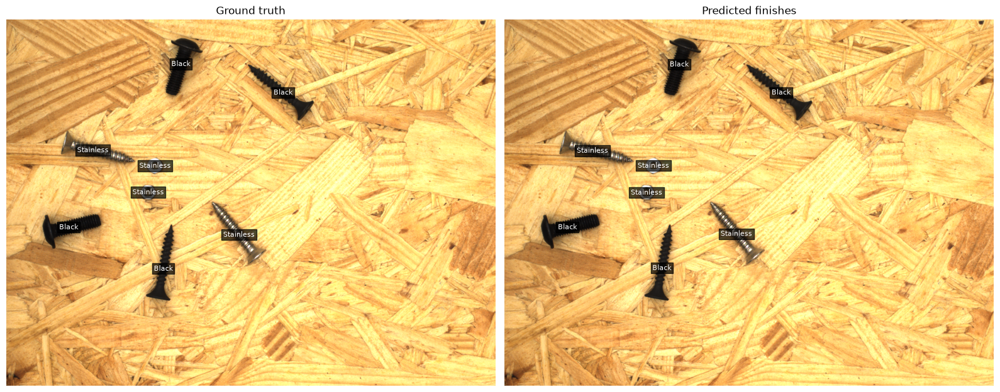

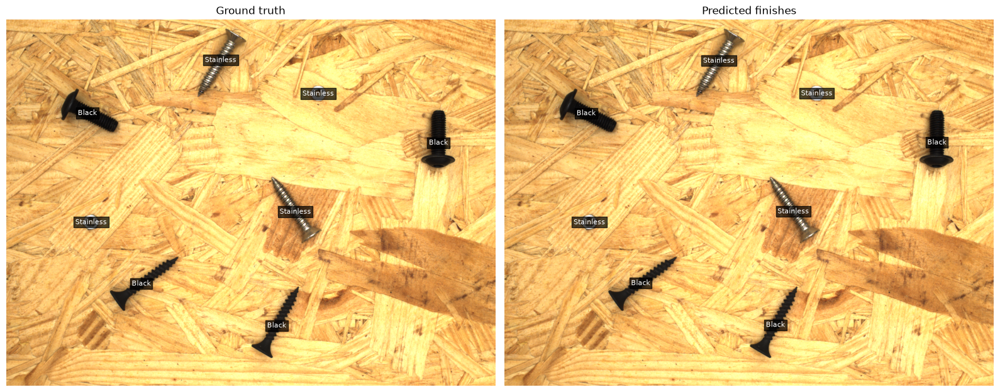

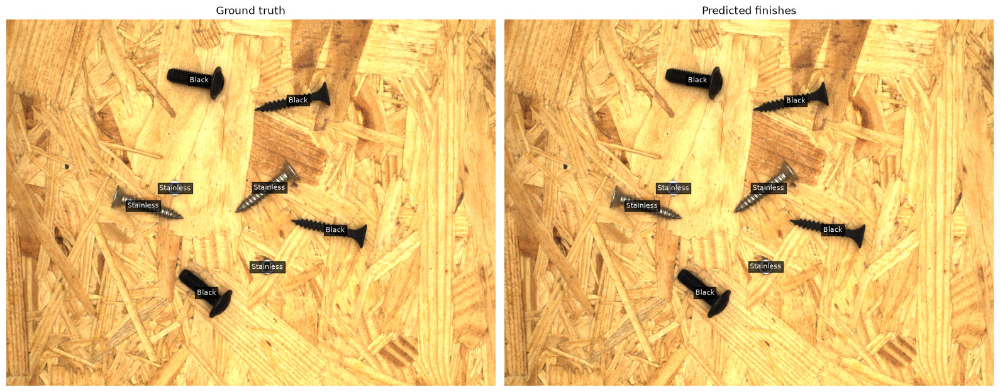

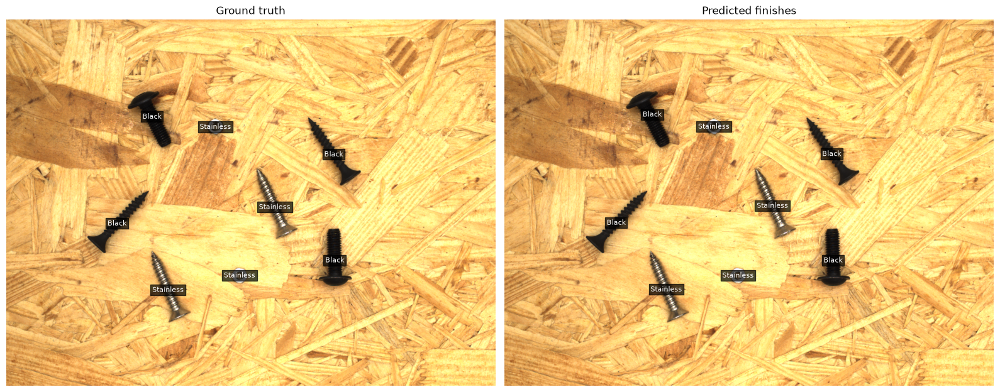

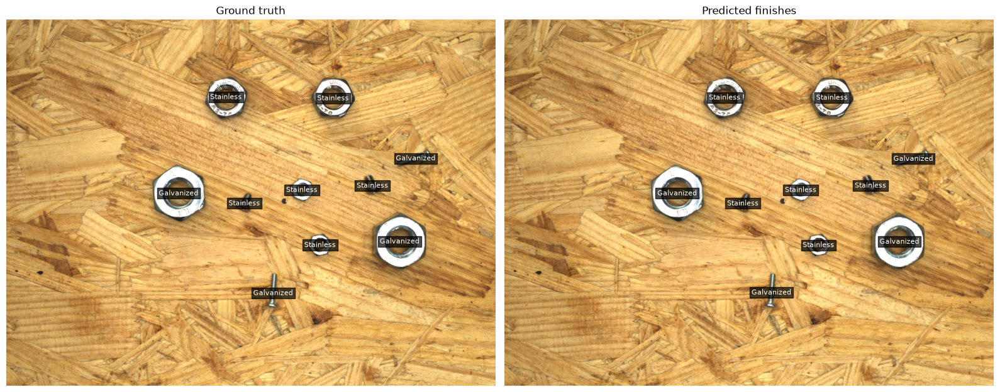

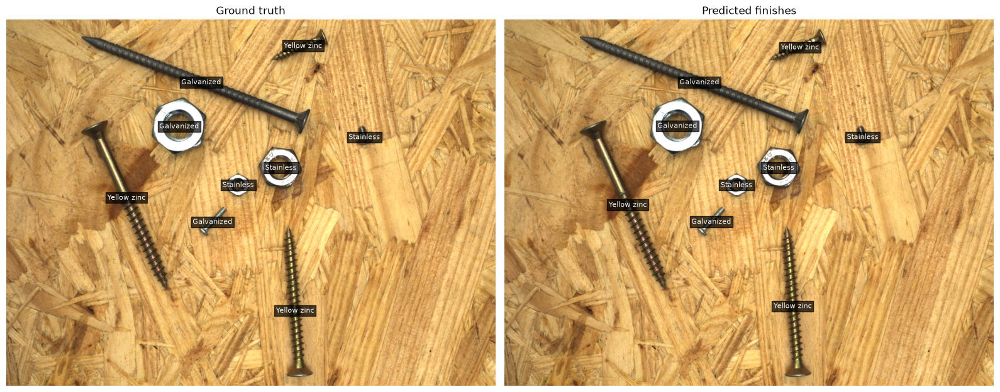

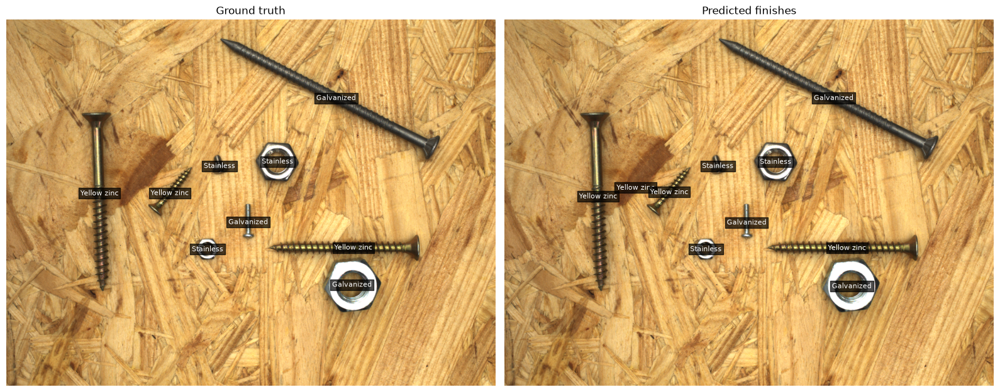

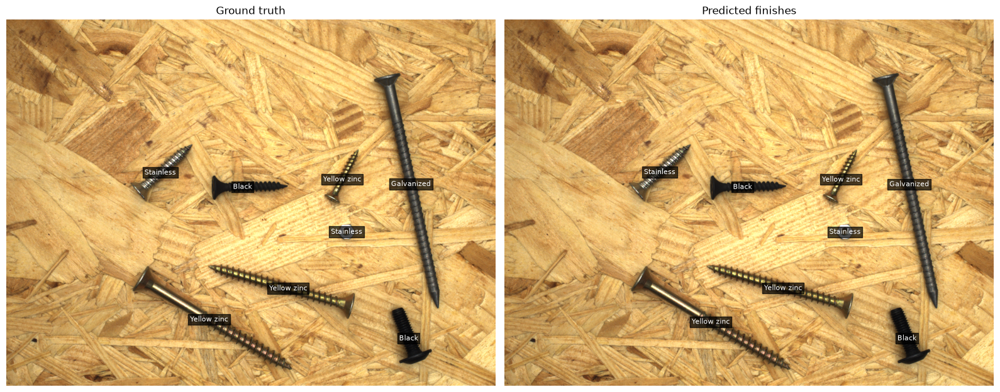

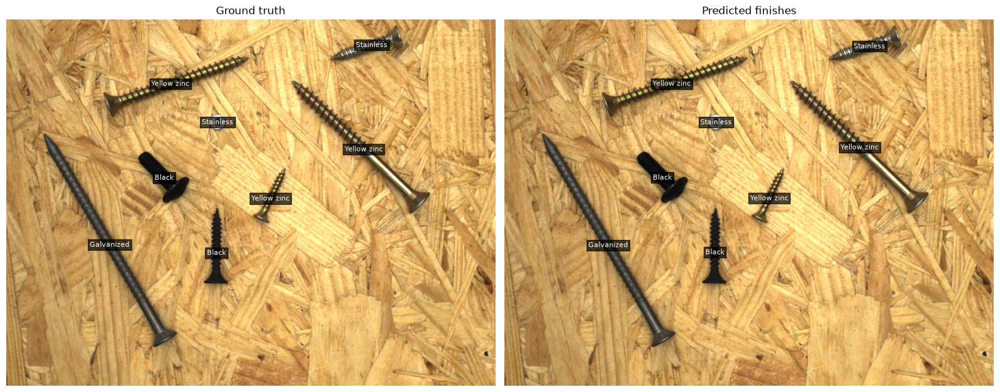

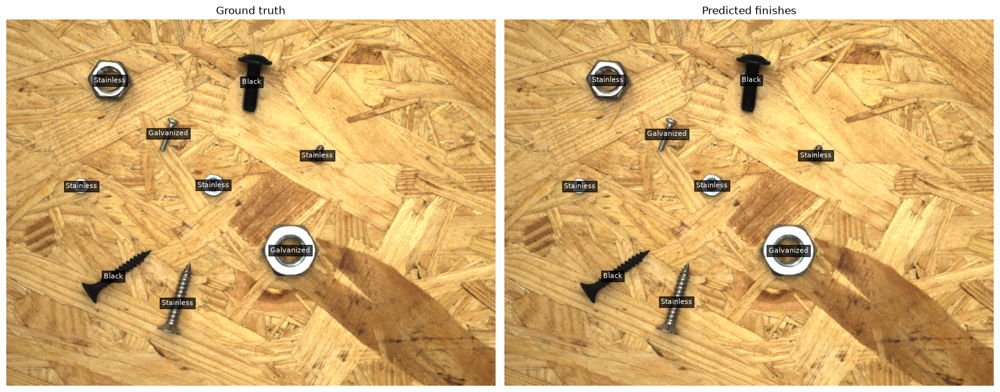

In [60]:
for image_name in sorted(finish_results["image"].unique()):

    image_path = Path("inputs") / image_name
    gt_path = Path("annotations") / (
        f"{image_path.stem}_labels.png"
    )

    if gt_path.exists():
        show_finish_comparison(
            image_path,
            parts_df,
            finish_results
        )